**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import shutil

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:
job_name = "dense_v4_0per"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "dense_v4"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 0.0,
    "moco_attn": False, 
    "dense": True,                
    
    "simple_proj": False,                                                           
    "hidden_channels_dim": 128,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,

    "do_encoder": True,                        # latente autoencoder + pooling di moco
    "do_pre_proj": True,                        # dopo conv + pooling, prima del proiettore
    "do_proj_raw": True,                       # dopo il proiettore, prima della normalizzazione
    "do_post_proj": True,                      # dopo la normalizzazione (come contrastive_loss)
    "do_dense": True, 
    "do_sim_stats": True,
    
    "pca_encoder": None,
    "pca_pre_proj": None,         
    "pca_proj_raw": None,
    "pca_post_proj": None,


    "whitening": "lw",                         # "pca" | "ledoitwolf"
    "fit_on_train": True,                       # True: fit su tutte le serie di train di moco
    "max_fit_series": 0,                        # 0 = tutte; altrimenti campione casuale (ocsvm lento con molte serie)
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "600Gi"}
    }
]

**BUILD ENVIRONMENT**

In [3]:
ocsvm_func = project.new_function(
    name=f'ocsvm_all4',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:ad_ocsvm4",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [4]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-06 09:18:12,671 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 87057d4cc4b040708c53bc997526bd60 to finish...
2026-11-06 09:18:17,678 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 87057d4cc4b040708c53bc997526bd60 to finish...
2026-11-06 09:18:22,687 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 87057d4cc4b040708c53bc997526bd60 to finish...
2026-11-06 09:18:27,698 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 87057d4cc4b040708c53bc997526bd60 to finish...
2026-11-06 09:18:32,811 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 87057d4cc4b040708c53bc997526bd60 to finish...
2026-11-06 09:18:37,821 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 87057d4cc4b040708c53bc997526bd60 to finish...
2026-11-06 09:18:42,830 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 87057d4cc4b040708c53bc997526bd60 to finish...
2026-11-06 09

Run anomaly detection ocsvm: 87057d4cc4b040708c53bc997526bd60


In [5]:
from IPython.display import display

RESULTS_DIR = f"/tmp/anomaly_results_ocsvm_{job_name}"           # una cartella per job
shutil.rmtree(RESULTS_DIR, ignore_errors=True)

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download(f"{RESULTS_DIR}.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
punti = list(summary["punti"].keys())                              # solo i punti calcolati in questa run
print(f"job: {job_name} | moco: {summary['moco_version']} | punti: {', '.join(punti)}", "\n")

dati = {}          # punto -> (results, df), per i grafici
righe = []

for punto in punti:
    with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{RESULTS_DIR}/{punto}/scores.csv")
    dati[punto] = (results, df)

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    print(f"===== {punto} =====")
    print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}")
    print(f"whitening: {results.get('whitening', 'pca')} | componenti: {results['n_componenti']} | shrinkage: {results.get('shrinkage')}")
    print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']:.3f}")
    print(f"min_flood_area = {results['min_flood_area']:.3f}")
    print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
    print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}")
    print(f"AUROC: {results['auroc']:.3f}")

    display(pd.DataFrame(results["rules"]).T)                      # regole del punto

    righe.append({"punto": punto, "componenti": results["n_componenti"],
                  "shrinkage": results.get("shrinkage"), "AUROC": results["auroc"]})

# confronto tra i punti
print("===== CONFRONTO =====")
pd.DataFrame(righe).set_index("punto").round(3)

job: dense_v4_0per | moco: dense_v4 | punti: encoder, pre_proj, proj_raw, post_proj, dense, sim_stats 

===== encoder =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 512 | shrinkage: 0.0024228534744755678
nu: 0.05 | gamma: scale | dim: 512 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 26.7015 ± 17.4207
score anomale: 1.7694 ± 14.8177
AUROC: 0.855


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-4.092149,978.0,107.0,1424.0,2295.0,0.044546,0.592839,0.407161,0.901382,0.560941
FA 10%,1.884100,1338.0,196.0,1064.0,2206.0,0.081599,0.442964,0.557036,0.872229,0.679878
FA 15%,6.747321,1556.0,325.0,846.0,2077.0,0.135304,0.352206,0.647794,0.827220,0.726594
FA 20%,10.229344,1711.0,451.0,691.0,1951.0,0.187760,0.287677,0.712323,0.791397,0.749781
FA 25%,13.568295,1855.0,571.0,547.0,1831.0,0.237719,0.227727,0.772273,0.764633,0.768434
FA 30%,16.678342,1954.0,710.0,448.0,1692.0,0.295587,0.186511,0.813489,0.733483,0.771417


===== pre_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 4096 | shrinkage: 0.01384521147074707
nu: 0.05 | gamma: scale | dim: 4096 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 19.1103 ± 18.0584
score anomale: -0.9355 ± 15.7540
AUROC: 0.793


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-15.332652,575.0,86.0,1827.0,2316.0,0.035803,0.760616,0.239384,0.869894,0.375449
FA 10%,-9.416327,898.0,192.0,1504.0,2210.0,0.079933,0.626145,0.373855,0.823853,0.514318
FA 15%,-4.137041,1165.0,306.0,1237.0,2096.0,0.127394,0.514988,0.485012,0.791978,0.601601
FA 20%,0.215576,1361.0,424.0,1041.0,1978.0,0.176520,0.433389,0.566611,0.762465,0.650107
FA 25%,4.244946,1544.0,536.0,858.0,1866.0,0.223147,0.357202,0.642798,0.742308,0.688978
FA 30%,8.128780,1689.0,662.0,713.0,1740.0,0.275604,0.296836,0.703164,0.718418,0.710709


===== proj_raw =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.008819683829681875
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.049
min_flood_area = 0.000
score normali: 12.9112 ± 7.4125
score anomale: 6.7939 ± 6.6785
AUROC: 0.729


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1.662407,265.0,84.0,2137.0,2318.0,0.034971,0.889675,0.110325,0.759312,0.192657
FA 10%,0.640305,503.0,193.0,1899.0,2209.0,0.080350,0.790591,0.209409,0.722701,0.324726
FA 15%,3.400451,862.0,332.0,1540.0,2070.0,0.138218,0.641132,0.358868,0.721943,0.479422
FA 20%,5.479426,1128.0,445.0,1274.0,1957.0,0.185262,0.530391,0.469609,0.717101,0.567547
FA 25%,7.361883,1360.0,573.0,1042.0,1829.0,0.238551,0.433805,0.566195,0.703570,0.627451
FA 30%,8.831203,1524.0,689.0,878.0,1713.0,0.286844,0.365529,0.634471,0.688658,0.660455


... (4 outputs left out)

===== sim_stats =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 6 | shrinkage: 0.0006865578438776787
nu: 0.05 | gamma: scale | dim: 6 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 10.1025 ± 5.5190
score anomale: 10.1695 ± 5.6387
AUROC: 0.491


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1.458416,119.0,108.0,2283.0,2294.0,0.044963,0.950458,0.049542,0.524229,0.090529
FA 10%,2.991495,241.0,220.0,2161.0,2182.0,0.091590,0.899667,0.100333,0.522777,0.168355
FA 15%,5.298692,350.0,346.0,2052.0,2056.0,0.144047,0.854288,0.145712,0.502874,0.225952
FA 20%,6.727365,450.0,470.0,1952.0,1932.0,0.195670,0.812656,0.187344,0.489130,0.270921
FA 25%,7.933199,562.0,593.0,1840.0,1809.0,0.246878,0.766028,0.233972,0.486580,0.315997
FA 30%,8.855180,664.0,711.0,1738.0,1691.0,0.296003,0.723564,0.276436,0.482909,0.351602


===== CONFRONTO =====


,componenti,shrinkage,AUROC
punto,,,
encoder,512,0.002,0.855
pre_proj,4096,0.014,0.793
proj_raw,256,0.009,0.729
post_proj,256,0.003,0.668
dense,4096,0.002,0.703
sim_stats,6,0.001,0.491


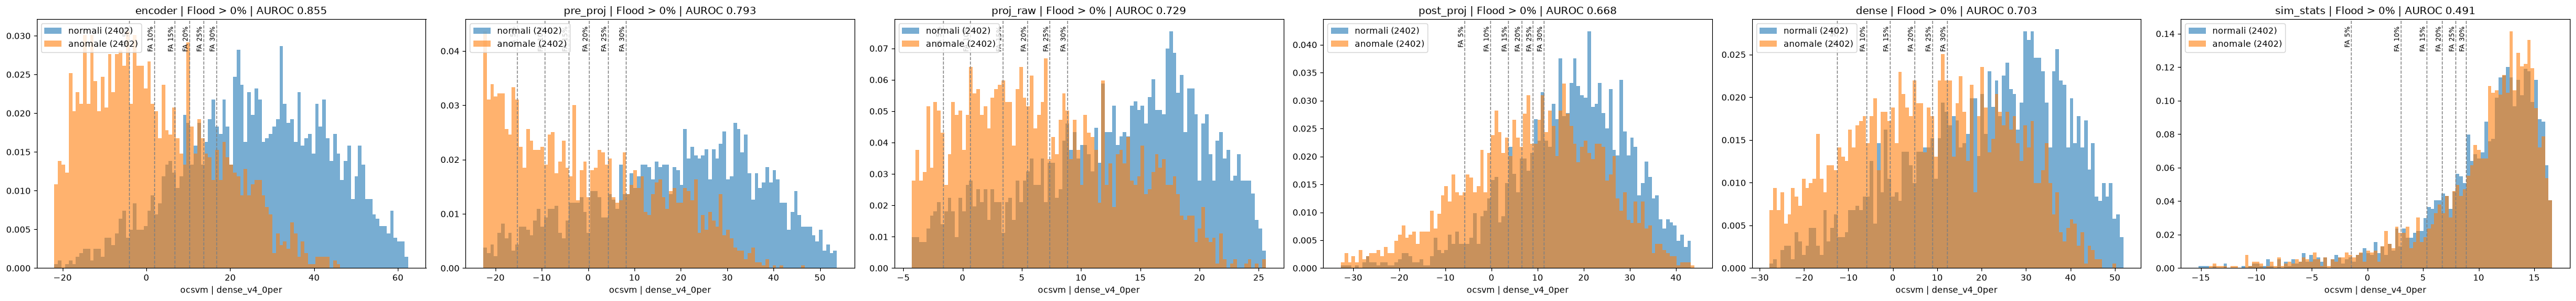

In [6]:
fig, axes = plt.subplots(1, len(punti), figsize=(7 * len(punti), 5), squeeze=False)

for ax, punto in zip(axes[0], punti):
    results, df = dati[punto]
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(f"ocsvm | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"{punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}")

plt.tight_layout()
plt.show()

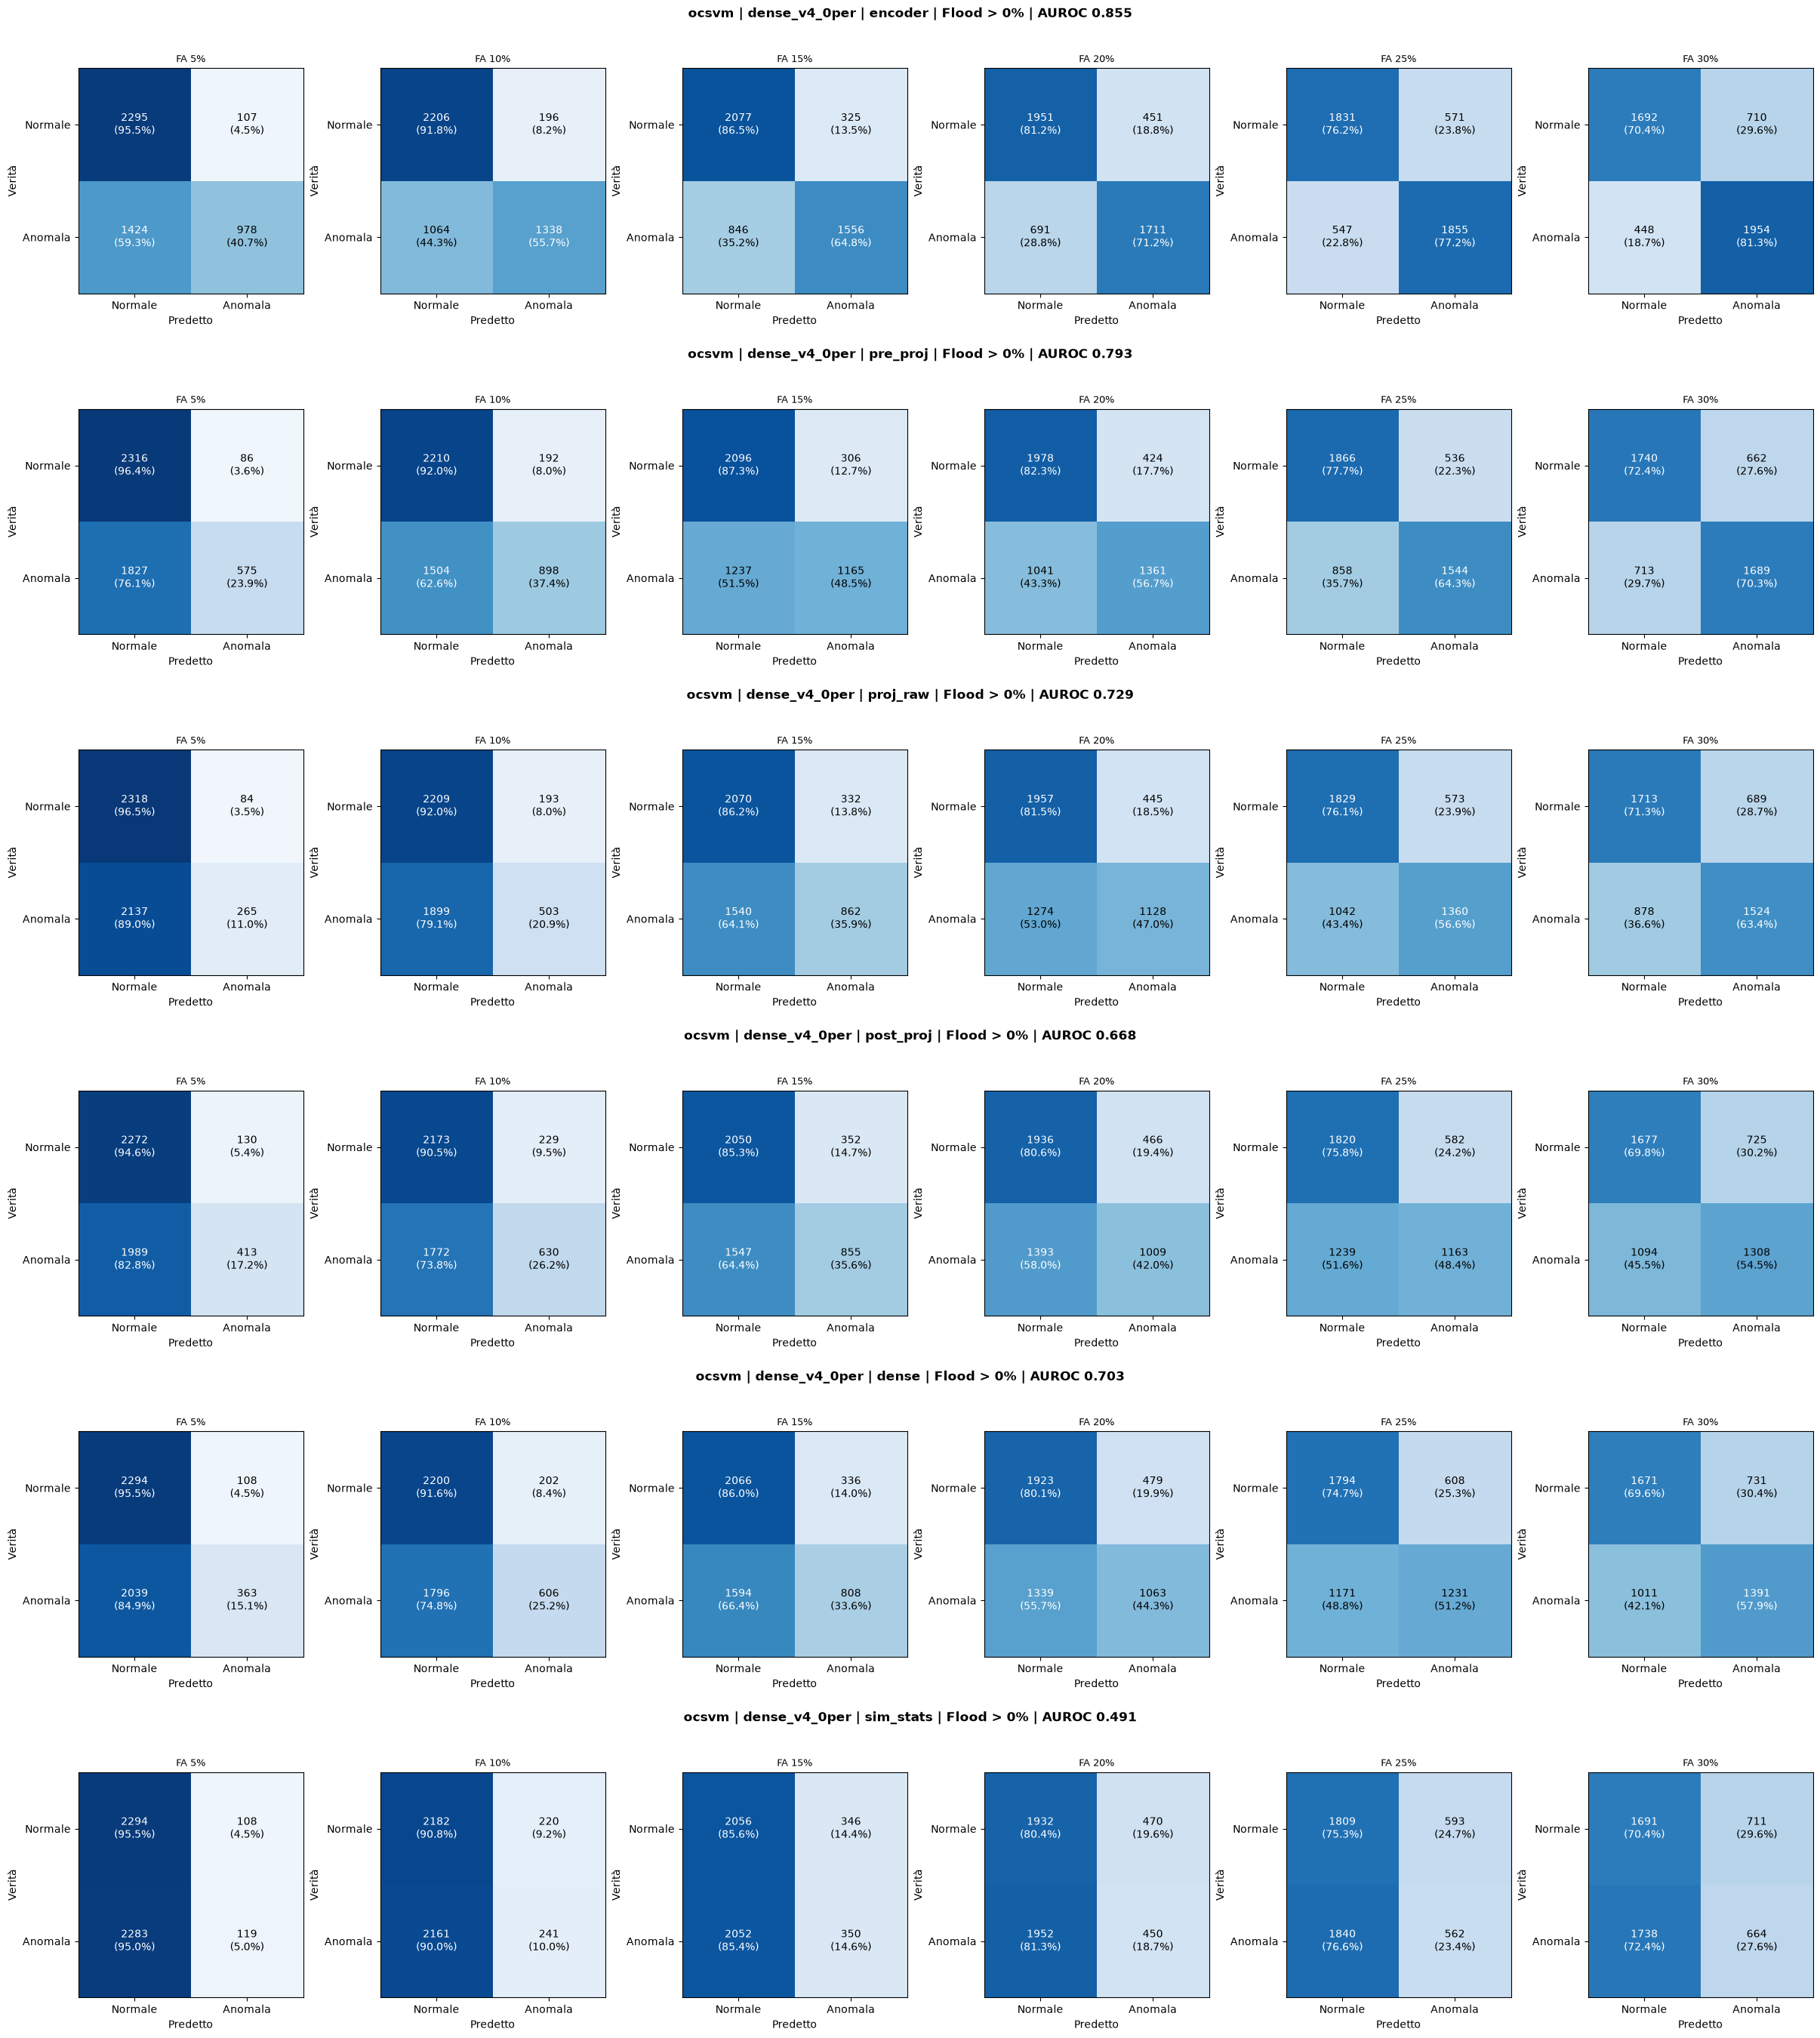

In [7]:
n_cols = max(len(dati[p][0]["rules"]) for p in punti)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * len(punti)), layout="constrained")
subfigs = np.atleast_1d(fig.subfigures(len(punti), 1))

for sfig, punto in zip(subfigs, punti):
    results, _ = dati[punto]
    rules = results["rules"]
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"ocsvm | {job_name} | {punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}",
                  fontsize=12, fontweight="bold")

plt.show()

In [8]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

punto = "pre_proj"

# verifica dei risultati caricati
with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
    info = json.load(f)

print(f"cartella:      {RESULTS_DIR}")
print(f"job:           {summary['job_name']} | moco: {summary['moco_version']} | dataset anomalie: {summary['dataset_anomalies']}")
print(f"fit_on_train:  {summary.get('fit_on_train')} | punti nella run: {', '.join(summary['punti'].keys())}")
print(f"punto:         {info['feature_point']} | min_flood_area: {info['min_flood_area']}")
print(f"serie:         fit {info['n_fit']} | thr {info['n_thr']} | normali {info['n_normali']} | anomale {info['n_anomale']}")
print(f"AUROC nel job: {info['auroc']:.3f} ({info['metodo']}, whitening {info.get('whitening', 'pca')}, {info['n_componenti']} componenti)", "\n")

E = np.load(f"{RESULTS_DIR}/{punto}/embeddings.npz")
cat = lambda g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)

w = {g: cat(g) for g in ("fit", "thr", "normal", "anom")}
print("forme:", {g: v.shape for g, v in w.items()}, "\n")

scaler = StandardScaler().fit(w["fit"])
w = {g: scaler.transform(v) for g, v in w.items()}

pca = PCA(whiten=True).fit(w["fit"])                     # una sola PCA con tutte le componenti
z = {g: pca.transform(v) for g, v in w.items()}


rng = np.random.default_rng(0)
ia = rng.permutation(len(z["anom"]));   a_val, a_test = ia[: len(ia) // 2], ia[len(ia) // 2:]
i_n = rng.permutation(len(z["normal"])); n_val, n_test = i_n[: len(i_n) // 2], i_n[len(i_n) // 2:]

def auroc(md, n_idx, a_idx):
    y = np.r_[np.zeros(len(n_idx)), np.ones(len(a_idx))]
    return roc_auc_score(y, np.r_[md["normal"][n_idx], md["anom"][a_idx]])

righe = []
for k in (32, 64, 128, 256, 512, 768, 1024, 1536, 2048, 3072, 4096):
    if k > z["fit"].shape[1]:
        break
    md = {g: (v[:, :k] ** 2).sum(1) for g, v in z.items()}         
    righe.append({
        "k": k,
        "thr/fit": md["thr"].mean() / md["fit"].mean(),  
        "AUROC": auroc(md, n_val, a_val),                
    })


lw = LedoitWolf().fit(w["fit"])
md = {g: lw.mahalanobis(v) for g, v in w.items()}                   
righe.append({
    "k": f"LW ({w['fit'].shape[1]})",
    "thr/fit": md["thr"].mean() / md["fit"].mean(),
    "AUROC": auroc(md, n_val, a_val),
})
print(f"Ledoit-Wolf shrinkage: {lw.shrinkage_:.3f}")

scelta = pd.DataFrame(righe).set_index("k")
print(scelta.round(3))

cartella:      /tmp/anomaly_results_ocsvm_dense_v4_0per
job:           dense_v4_0per | moco: dense_v4 | dataset anomalie: Floods_Anomalies_v3_crop_norm
fit_on_train:  True | punti nella run: encoder, pre_proj, proj_raw, post_proj, dense, sim_stats
punto:         pre_proj | min_flood_area: 0.0
serie:         fit 19893 | thr 2572 | normali 2402 | anomale 2402
AUROC nel job: 0.793 (ocsvm, whitening lw, 4096 componenti) 

forme: {'fit': (19893, 4096), 'thr': (2572, 4096), 'normal': (2402, 4096), 'anom': (2402, 4096)} 

Ledoit-Wolf shrinkage: 0.014
           thr/fit  AUROC
k                        
32           1.139  0.650
64           1.098  0.684
128          1.061  0.706
256          1.039  0.730
512          1.016  0.748
768          1.003  0.759
1024         1.003  0.766
1536         1.023  0.772
2048         1.061  0.777
3072         1.190  0.783
4096         1.400  0.786
LW (4096)    1.354  0.786
